# Réseau Analogique — Classification Disque — v4 (MAX SPEED)

**Problème** : classifier des points à l'intérieur vs l'extérieur d'un disque centré de rayon 0.5.

Accélérations :
  - `layer_forward`         : Numba JIT (`@njit`) — supprime la double boucle Python
  - `interp2d_bilinear`     : Numba JIT — interpolation compilée
  - `network_forward_mc`    : CuPy GPU — tirages Monte-Carlo en parallèle sur GPU
  - `coordinate_search`     : joblib — candidats évalués en parallèle sur N cœurs
  - `restarts`              : joblib — restarts indépendants en parallèle
  - `MIN_MARGIN_HZ = 1kHz`  : pénalité dure si marge < 1 kHz (contrainte physique)

**Fix v4.1** : Correction du comportement neuronal pour courants négatifs.  
Un neurone avec `Itot < I_rheobase` ne spike pas → `Fout = 0 Hz` (et non 3 kHz).

Exécuter les cellules dans l'ordre (`Kernel → Restart & Run All`).  
Première exécution plus lente : Numba compile les fonctions JIT au premier appel.

## 0. Imports & Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
import time
import warnings
warnings.filterwarnings('ignore')

from numba import njit, prange
import joblib
from tqdm.auto import tqdm, trange
try:
    import cupy as cp
    GPU_AVAILABLE = True
    print('GPU détecté :', cp.cuda.runtime.getDeviceProperties(0)['name'].decode())
except Exception:
    cp = None
    GPU_AVAILABLE = False
    print('GPU non disponible — Monte-Carlo sur CPU.')

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size']  = 11
np.set_printoptions(precision=4, suppress=True)

# ── Fichiers CSV ──────────────────────────────────────────────
INPUT_CSV   = 'input_min_conso.csv'
NEURON_CSV  = 'neuron.csv'
SYN_EXC_CSV = 'excitation20.csv'
SYN_INH_CSV = 'inhibition20.csv'

FREQ_MERGE_TOL_HZ = 1000.0

# ── Architecture  [2, N_hidden, 2] ───────────────────────────
HIDDEN_SIZES = [8,8]   # ex: [4] -> 2-4-2  |  [4,4] -> 2-4-4-2

# ── Recherche ────────────────────────────────────────────────
N_RESTARTS   = 8
MAX_PASSES   = 8
SEED         = 42
N_JOBS       = -1    # -1 = tous les cœurs CPU disponibles

# ── Dataset Disque ────────────────────────────────────────────
N_TRAIN     = 400
N_TEST      = 200
DISK_RADIUS = 0.5   # rayon du disque en coordonnées normalisées [-1, 1]
MARGIN      = 0.05  # zone d'exclusion autour du bord du disque

# ── Score avec contrainte physique 1 kHz ─────────────────────
# Plage fréquence hardware : 3 kHz – 193.1 kHz
MARGIN_SCALE       = 1e-4
IMBALANCE_PENALTY  = 0.15
MIN_MARGIN_HZ      = 1000.0
MIN_MARGIN_PENALTY = 0.5

# ── Robustesse au bruit ───────────────────────────────────────
NOISE_STD_HZ = 500.0
N_MC_TRAIN   = 5
N_MC_EVAL    = 30

print('Configuration OK.')

GPU détecté : NVIDIA GeForce RTX 3080
Configuration OK.


## 1. Fonctions utilitaires

In [2]:
def progress_bar(current, total, prefix='', suffix='', bar_len=35):
    filled = int(bar_len * current / total)
    bar    = '█' * filled + '░' * (bar_len - filled)
    pct    = int(100 * current / total)
    sys.stdout.write('\r  ' + prefix + '[' + bar + '] '
                     + str(current) + '/' + str(total)
                     + ' (' + str(pct) + '%)  ' + suffix)
    sys.stdout.flush()
    if current == total:
        sys.stdout.write('\n')
        sys.stdout.flush()

def read_cadence_rows(csv_path):
    df = pd.read_csv(csv_path)
    if 'Parameter' not in df.columns:
        raise ValueError(csv_path + ": colonne 'Parameter' introuvable")
    data_cols = [c for c in df.columns if c not in ['Parameter', 'Unnamed: 1']]
    def get_row(row_name, allow_non_numeric=False):
        row = df.loc[df['Parameter'] == row_name, data_cols]
        if row.empty:
            raise ValueError("Ligne '" + row_name + "' introuvable dans " + csv_path)
        values = pd.to_numeric(row.iloc[0], errors='coerce').to_numpy(dtype=float)
        if not allow_non_numeric and np.isnan(values).any():
            raise ValueError("Ligne '" + row_name + "' contient des NaN")
        return values
    return get_row

def get_clean_rows(reader, row_names):
    rows = [reader(name, allow_non_numeric=True) for name in row_names]
    mask = np.all(np.isfinite(np.vstack(rows)), axis=0)
    return [r[mask] for r in rows], mask

def interp_clip(x, xp, fp):
    return np.interp(np.asarray(x, float), xp, fp, left=fp[0], right=fp[-1])

def strictly_monotonic_branch(x, y):
    idx = int(np.argmax(y))
    xm, ym = np.asarray(x[:idx+1], float), np.asarray(y[:idx+1], float)
    o = np.argsort(xm)
    return xm[o], ym[o]

def merge_close_values(values, tol):
    vals = np.sort(np.asarray(values, float))
    groups = [[vals[0]]]
    for v in vals[1:]:
        if abs(v - np.mean(groups[-1])) <= tol:
            groups[-1].append(v)
        else:
            groups.append([v])
    return np.array([np.mean(g) for g in groups])

def snap_to_axis(values, axis):
    return np.array([axis[np.argmin(np.abs(axis - v))]
                     for v in np.asarray(values, float)])

def build_grid_tolerant(W_all, F_all, Y_all, freq_tol=1000.0):
    W_all, F_all, Y_all = (np.asarray(a, float) for a in (W_all, F_all, Y_all))
    W_unique = np.unique(W_all)
    F_axis   = merge_close_values(np.unique(F_all), tol=freq_tol)
    F_snap   = snap_to_axis(F_all, F_axis)
    z_grid   = np.empty((len(W_unique), len(F_axis)))
    for i, w in enumerate(W_unique):
        for j, f in enumerate(F_axis):
            mask = np.isclose(W_all, w) & np.isclose(F_snap, f)
            if not mask.any():
                raise ValueError('Point manquant W=' + str(w) + ' F=' + str(f))
            z_grid[i, j] = np.mean(Y_all[mask])
    return W_unique, F_axis, z_grid

print('Fonctions utilitaires OK.')

Fonctions utilitaires OK.


## 2. Chargement des modèles Cadence

In [3]:
inp = read_cadence_rows(INPUT_CSV)
VEX_IN, FSPIKES_IN = inp('Vex'), inp('Fspikes')
INPUT_V_AXIS, INPUT_F_AXIS = strictly_monotonic_branch(VEX_IN, FSPIKES_IN)

neuro = read_cadence_rows(NEURON_CSV)
IEX_NEURO, FSPIKES_NEURO = neuro('Iex'), neuro('Fspikes')
NEURON_I_AXIS, NEURON_F_AXIS = strictly_monotonic_branch(IEX_NEURO, FSPIKES_NEURO)

syn_exc = read_cadence_rows(SYN_EXC_CSV)
(W2_EXC, FPRE_EXC, IPOST_EXC), _ = get_clean_rows(syn_exc, ['W2', 'Fpre', 'Ipost'])
W_EXC_AXIS, F_EXC_AXIS, IPOST_EXC_GRID = build_grid_tolerant(
    W2_EXC, FPRE_EXC, IPOST_EXC, FREQ_MERGE_TOL_HZ)

syn_inh = read_cadence_rows(SYN_INH_CSV)
(W2_INH, FPRE_INH, IPOST_INH), _ = get_clean_rows(syn_inh, ['W2', 'Fpre', 'Ipost'])
W_INH_AXIS, F_INH_AXIS, IPOST_INH_GRID = build_grid_tolerant(
    W2_INH, FPRE_INH, IPOST_INH, FREQ_MERGE_TOL_HZ)

V_MIN       = float(INPUT_V_AXIS[0])
V_MAX       = float(INPUT_V_AXIS[-1])
LAYER_SIZES = [2] + HIDDEN_SIZES + [2]

NEURON_I_RHEOBASE = float(NEURON_I_AXIS[0])

_INPUT_V_AXIS   = np.ascontiguousarray(INPUT_V_AXIS,   dtype=np.float64)
_INPUT_F_AXIS   = np.ascontiguousarray(INPUT_F_AXIS,   dtype=np.float64)
_NEURON_I_AXIS  = np.ascontiguousarray(NEURON_I_AXIS,  dtype=np.float64)
_NEURON_F_AXIS  = np.ascontiguousarray(NEURON_F_AXIS,  dtype=np.float64)
_W_EXC_AXIS     = np.ascontiguousarray(W_EXC_AXIS,     dtype=np.float64)
_F_EXC_AXIS     = np.ascontiguousarray(F_EXC_AXIS,     dtype=np.float64)
_IPOST_EXC_GRID = np.ascontiguousarray(IPOST_EXC_GRID, dtype=np.float64)
_W_INH_AXIS     = np.ascontiguousarray(W_INH_AXIS,     dtype=np.float64)
_F_INH_AXIS     = np.ascontiguousarray(F_INH_AXIS,     dtype=np.float64)
_IPOST_INH_GRID = np.ascontiguousarray(IPOST_INH_GRID, dtype=np.float64)
_F_MAX          = float(NEURON_F_AXIS[-1])

print('Input  V : ' + str(round(V_MIN*1e3,1)) + ' mV -> ' + str(round(V_MAX*1e3,1)) + ' mV')
print('Neuron I : ' + str(round(NEURON_I_AXIS[0]*1e12,1))
      + ' pA -> ' + str(round(NEURON_I_AXIS[-1]*1e12,1)) + ' pA')
print('Neuron rheobase (I_min spike) : ' + str(round(NEURON_I_RHEOBASE*1e12,2)) + ' pA')
print('Exc W (um) : ' + str(W_EXC_AXIS))
print('Inh W (um) : ' + str(W_INH_AXIS))
print('Architecture : ' + str(LAYER_SIZES))

Input  V : -100.0 mV -> 100.0 mV
Neuron I : 3.0 pA -> 1000.0 pA
Neuron rheobase (I_min spike) : 3.0 pA
Exc W (um) : [0.135  0.2858 0.4366 0.5874 0.7382 0.8889 1.04   1.191  1.341  1.492
 1.643  1.794  1.944  2.095  2.246  2.397  2.548  2.698  2.849  3.    ]
Inh W (um) : [0.135  0.1805 0.2261 0.2716 0.3171 0.3626 0.4082 0.4537 0.4992 0.5447
 0.5903 0.6358 0.6813 0.7268 0.7724 0.8179 0.8634 0.9089 0.9545 1.    ]
Architecture : [2, 8, 8, 2]


## 3. Noyaux Numba JIT

Ces fonctions sont compilées en C au premier appel (~2s), puis très rapides.

**Fix v4.1** : `_interp1d_numba` retourne maintenant `0.0` quand `x < xp[0]`  
(i.e. courant inférieur à la rheobase → neurone silencieux, pas de spiking).

In [4]:
@njit(cache=True)
def _interp1d_numba(x, xp, fp):
    """
    Interpolation 1D compilée Numba.
    FIX v4.1 : retourne 0.0 si x < xp[0] → neurone silencieux sous le seuil.
    """
    if x <= xp[0]:
        return 0.0
    if x >= xp[-1]:
        return fp[-1]
    lo, hi = 0, len(xp) - 1
    while hi - lo > 1:
        mid = (lo + hi) // 2
        if xp[mid] <= x:
            lo = mid
        else:
            hi = mid
    t = (x - xp[lo]) / (xp[hi] - xp[lo])
    return fp[lo] + t * (fp[hi] - fp[lo])


@njit(cache=True)
def _interp2d_numba(x, y, x_axis, y_axis, z_grid):
    """Interpolation bilinéaire compilée Numba."""
    x = max(x_axis[0], min(x_axis[-1], x))
    y = max(y_axis[0], min(y_axis[-1], y))
    lx, hx = 0, len(x_axis) - 2
    for k in range(len(x_axis) - 1):
        if x_axis[k] <= x < x_axis[k+1]:
            lx = k
            break
    else:
        lx = len(x_axis) - 2
    ly = 0
    for k in range(len(y_axis) - 1):
        if y_axis[k] <= y < y_axis[k+1]:
            ly = k
            break
    else:
        ly = len(y_axis) - 2
    x1, x2 = x_axis[lx], x_axis[lx+1]
    y1, y2 = y_axis[ly], y_axis[ly+1]
    tx = 0.0 if x2 == x1 else (x - x1) / (x2 - x1)
    ty = 0.0 if y2 == y1 else (y - y1) / (y2 - y1)
    return (z_grid[lx,   ly  ] * (1-tx) * (1-ty) +
            z_grid[lx+1, ly  ] * tx     * (1-ty) +
            z_grid[lx,   ly+1] * (1-tx) * ty     +
            z_grid[lx+1, ly+1] * tx     * ty)


@njit(cache=True, parallel=True)
def _layer_forward_numba(Fin, signs_flat, widths_flat, N, M,
                          w_exc, f_exc, g_exc,
                          w_inh, f_inh, g_inh,
                          ni_axis, nf_axis):
    """
    Layer forward entièrement compilé Numba avec parallélisme sur les synapses.
    """
    Iconn = np.zeros(N * M)
    for k in prange(N * M):
        i = k // M
        j = k  % M
        s = signs_flat[k]
        w = widths_flat[k]
        f = Fin[i]
        if s == 1:
            Iconn[k] = _interp2d_numba(w, f, w_exc, f_exc, g_exc)
        elif s == -1:
            Iconn[k] = -_interp2d_numba(w, f, w_inh, f_inh, g_inh)

    Itot = np.zeros(M)
    for k in range(N * M):
        j = k % M
        Itot[j] += Iconn[k]

    Fout = np.empty(M)
    for j in range(M):
        Fout[j] = _interp1d_numba(Itot[j], ni_axis, nf_axis)

    return Fout, Iconn.reshape((N, M)), Itot


def layer_forward(Fin_vec_Hz, sign_matrix, width_matrix_um):
    """Wrapper Python de _layer_forward_numba."""
    N, M = sign_matrix.shape
    Fout, Iconn, Itot = _layer_forward_numba(
        np.ascontiguousarray(Fin_vec_Hz, np.float64),
        sign_matrix.ravel().astype(np.float64),
        width_matrix_um.ravel().astype(np.float64),
        N, M,
        _W_EXC_AXIS, _F_EXC_AXIS, _IPOST_EXC_GRID,
        _W_INH_AXIS, _F_INH_AXIS, _IPOST_INH_GRID,
        _NEURON_I_AXIS, _NEURON_F_AXIS
    )
    return Fout, Iconn, Itot


def input_f_of_v(Vin_V):
    return float(_interp1d_numba(float(Vin_V), _INPUT_V_AXIS, _INPUT_F_AXIS))

def neuron_f_of_i(Iin_A):
    if Iin_A < NEURON_I_RHEOBASE:
        return 0.0
    return float(_interp1d_numba(float(Iin_A), _NEURON_I_AXIS, _NEURON_F_AXIS))

def isyn_exc(Fpre_Hz, Wexc_um):
    return float(_interp2d_numba(Wexc_um, Fpre_Hz, _W_EXC_AXIS, _F_EXC_AXIS, _IPOST_EXC_GRID))

def isyn_inh(Fpre_Hz, Winh_um):
    return float(_interp2d_numba(Winh_um, Fpre_Hz, _W_INH_AXIS, _F_INH_AXIS, _IPOST_INH_GRID))


# ── Warm-up Numba ──────────────────────────────────────────────
print('Compilation Numba JIT (une seule fois)...')
t0 = time.time()
_dummy_signs  = np.array([[1.0, -1.0], [-1.0, 1.0]])
_dummy_widths = np.array([[float(W_EXC_AXIS[0]), float(W_INH_AXIS[0])],
                           [float(W_INH_AXIS[0]), float(W_EXC_AXIS[0])]])
_dummy_F      = np.array([1000.0, 2000.0])
layer_forward(_dummy_F, _dummy_signs, _dummy_widths)
print(f'  JIT compilé en {time.time()-t0:.1f}s — les prochains appels seront rapides.')

print('\n── Vérification fix courant négatif ──')
print(f'  neuron_f_of_i(-1e-9 A)  = {neuron_f_of_i(-1e-9):.1f} Hz  (attendu: 0.0)')
print(f'  neuron_f_of_i(0.0 A)    = {neuron_f_of_i(0.0):.1f} Hz  (attendu: 0.0)')
print(f'  neuron_f_of_i(rheobase) = {neuron_f_of_i(NEURON_I_RHEOBASE):.1f} Hz  (attendu: ~{NEURON_F_AXIS[0]:.0f})')

print('\nNoyaux Numba OK.')

Compilation Numba JIT (une seule fois)...
  JIT compilé en 0.2s — les prochains appels seront rapides.

── Vérification fix courant négatif ──
  neuron_f_of_i(-1e-9 A)  = 0.0 Hz  (attendu: 0.0)
  neuron_f_of_i(0.0 A)    = 0.0 Hz  (attendu: 0.0)
  neuron_f_of_i(rheobase) = 0.0 Hz  (attendu: ~3083)

Noyaux Numba OK.


## 4. Propagation CPU + GPU

In [5]:
def network_forward_single(Vin_vec_V, signs, widths):
    """Forward pass déterministe, un seul sample."""
    F = np.array([input_f_of_v(v) for v in Vin_vec_V])
    for sm, wm in zip(signs, widths):
        F, _, _ = layer_forward(F, sm, wm)
    return F

def network_forward_dataset(V_dataset, signs, widths):
    """Forward déterministe sur tout le dataset."""
    return np.array([network_forward_single(Vin, signs, widths) for Vin in V_dataset])


if GPU_AVAILABLE:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        """Monte-Carlo sur GPU (CuPy). Clamp inférieur = 0.0."""
        N      = len(V_dataset)
        n_out  = LAYER_SIZES[-1]
        Fout_cpu = network_forward_dataset(V_dataset, signs, widths)
        Fout_gpu = cp.asarray(Fout_cpu)
        noise    = cp.random.normal(0.0, noise_std, (n_mc, N, n_out))
        Fout_mc  = cp.clip(Fout_gpu[None, :, :] + noise, 0.0, _F_MAX)
        return cp.asnumpy(Fout_mc.mean(axis=0))
else:
    def network_forward_mc(V_dataset, signs, widths, noise_std, n_mc):
        """Monte-Carlo CPU fallback. Clamp inférieur = 0.0."""
        rng = np.random.default_rng()
        acc = np.zeros((len(V_dataset), LAYER_SIZES[-1]))
        for _ in range(n_mc):
            Fout = network_forward_dataset(V_dataset, signs, widths)
            acc += np.clip(Fout + rng.normal(0, noise_std, Fout.shape), 0, _F_MAX)
        return acc / n_mc


print('Propagation OK.')

Propagation OK.


## 5. Dataset Disque

Train : 400 pts  cl1(int)=68  cl0(ext)=332
Test  : 200 pts  cl1(int)=40  cl0(ext)=160


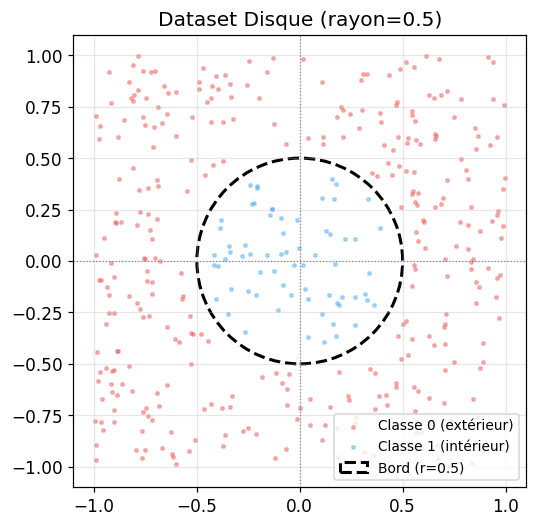

In [6]:
def label_disk(X, radius=DISK_RADIUS):
    """
    Classe 1 = intérieur du disque (r < radius)
    Classe 0 = extérieur du disque (r > radius)
    """
    return (X[:, 0]**2 + X[:, 1]**2 < radius**2).astype(int)

def make_dataset(n, seed=0):
    rng = np.random.default_rng(seed)
    pts = []
    while sum(len(p) for p in pts) < n:
        batch = rng.uniform(-1.0, 1.0, size=(n * 2, 2))
        # Exclure les points trop proches du bord du disque (zone ambiguë)
        r    = np.sqrt(batch[:, 0]**2 + batch[:, 1]**2)
        mask = np.abs(r - DISK_RADIUS) > MARGIN
        pts.append(batch[mask])
    data = np.vstack(pts)[:n]
    return data, label_disk(data)

def xy_to_voltage(X):
    return V_MIN + (np.asarray(X, float) + 1.0) * (V_MAX - V_MIN) / 2.0

X_train, y_train = make_dataset(N_TRAIN, seed=SEED)
X_test,  y_test  = make_dataset(N_TEST,  seed=SEED + 1)
V_train = xy_to_voltage(X_train)
V_test  = xy_to_voltage(X_test)

print('Train : ' + str(len(y_train)) + ' pts  cl1(int)=' + str(y_train.sum())
      + '  cl0(ext)=' + str((1-y_train).sum()))
print('Test  : ' + str(len(y_test))  + ' pts  cl1(int)=' + str(y_test.sum())
      + '  cl0(ext)=' + str((1-y_test).sum()))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X_train[y_train==0, 0], X_train[y_train==0, 1],
           s=5, alpha=0.4, c='#EF5350', label='Classe 0 (extérieur)')
ax.scatter(X_train[y_train==1, 0], X_train[y_train==1, 1],
           s=5, alpha=0.4, c='#42A5F5', label='Classe 1 (intérieur)')
circle = plt.Circle((0, 0), DISK_RADIUS, color='k', fill=False, lw=2, ls='--', label=f'Bord (r={DISK_RADIUS})')
ax.add_patch(circle)
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title(f'Dataset Disque (rayon={DISK_RADIUS})')
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Évaluation avec contrainte 1 kHz

In [7]:
def evaluate_network(V_dataset, y_true, signs, widths,
                     noise_std=0.0, n_mc=1):
    """
    noise_std=0, n_mc=1  ->  déterministe.
    noise_std>0, n_mc>1  ->  Monte-Carlo GPU si disponible.

    Score = bal_acc
            + MARGIN_SCALE * bal_margin          (récompense grande marge)
            - IMBALANCE_PENALTY * |acc0-acc1|    (pénalise déséquilibre classes)
            - MIN_MARGIN_PENALTY * frac_below    (pénalité dure si marge < 1kHz)
    """
    if noise_std > 0 and n_mc > 1:
        Fout = network_forward_mc(V_dataset, signs, widths, noise_std, n_mc)
    else:
        Fout = network_forward_dataset(V_dataset, signs, widths)

    preds = np.argmax(Fout, axis=1)
    y     = np.asarray(y_true, int)
    mask0, mask1 = (y == 0), (y == 1)

    acc0 = float(np.mean(preds[mask0] == 0)) if mask0.any() else 0.0
    acc1 = float(np.mean(preds[mask1] == 1)) if mask1.any() else 0.0
    bal_acc = 0.5 * (acc0 + acc1)

    margins = np.where(y == 1,
                       Fout[:, 1] - Fout[:, 0],
                       Fout[:, 0] - Fout[:, 1])
    margin0    = float(np.mean(margins[mask0])) if mask0.any() else 0.0
    margin1    = float(np.mean(margins[mask1])) if mask1.any() else 0.0
    bal_margin = 0.5 * (margin0 + margin1)

    frac_below = float(np.mean(margins < MIN_MARGIN_HZ))

    score = (bal_acc
             + MARGIN_SCALE      * bal_margin
             - IMBALANCE_PENALTY * abs(acc0 - acc1)
             - MIN_MARGIN_PENALTY * frac_below)

    return {'preds': preds, 'Fout': Fout,
            'acc0': acc0, 'acc1': acc1, 'bal_acc': bal_acc,
            'bal_margin': bal_margin, 'frac_below': frac_below,
            'score': score}


def print_results(label, m):
    print('\n=== ' + label + ' ===')
    print('  acc cl0 (ext) = ' + str(round(m['acc0'], 4)))
    print('  acc cl1 (int) = ' + str(round(m['acc1'], 4)))
    print('  bal_acc       = ' + str(round(m['bal_acc'], 4)))
    print('  marge moy.    = ' + str(round(m['bal_margin'] * 1e-3, 3)) + ' kHz')
    print('  pts < 1 kHz   = ' + str(round(m['frac_below'] * 100, 1)) + ' %')
    print('  score         = ' + str(round(m['score'], 6)))


ALL_CANDIDATES = [
    [(+1, float(w)) for w in W_EXC_AXIS] + [(-1, float(w)) for w in W_INH_AXIS]
    for _ in range(len(LAYER_SIZES) - 1)
]
print('Candidats par connexion : ' + str(len(ALL_CANDIDATES[0]))
      + ' (' + str(len(W_EXC_AXIS)) + ' EXC + ' + str(len(W_INH_AXIS)) + ' INH)')


def random_network(rng):
    signs, widths = [], []
    for li, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:])):
        exc_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == +1]
        inh_w = [c[1] for c in ALL_CANDIDATES[li] if c[0] == -1]
        s = rng.choice([-1, 1], size=(n_in, n_out))
        w = np.zeros((n_in, n_out))
        for i in range(n_in):
            for j in range(n_out):
                w[i, j] = rng.choice(exc_w if s[i, j] == 1 else inh_w)
        signs.append(s)
        widths.append(w)
    return signs, widths

print('evaluate_network OK.')

Candidats par connexion : 40 (20 EXC + 20 INH)
evaluate_network OK.


## 7. coordinate_search (un seul restart)

In [8]:
def _one_restart(restart_idx, rng_seed, pbar_restarts=None):
    """
    Un restart complet de coordinate search.
    """
    rng = np.random.default_rng(rng_seed)
    all_conns = [
        (l, i, j)
        for l, (n_in, n_out) in enumerate(zip(LAYER_SIZES[:-1], LAYER_SIZES[1:]))
        for i in range(n_in)
        for j in range(n_out)
    ]
    n_conns = len(all_conns)

    signs, widths = random_network(rng)
    tr = evaluate_network(V_train, y_train, signs, widths,
                          noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
    va = evaluate_network(V_test,  y_test,  signs, widths)

    history = [{'pass': 0,
                'tr_bal_acc': tr['bal_acc'], 'tr_score': tr['score'],
                'va_bal_acc': va['bal_acc'], 'va_score': va['score']}]
    t0 = time.time()

    R = f'R{restart_idx+1:02d}'
    print(f'  {R} démarré | tr_acc={tr["bal_acc"]:.3f} | va_acc={va["bal_acc"]:.3f}')

    for pass_idx in range(MAX_PASSES):
        improved   = False
        conn_order = list(all_conns)
        rng.shuffle(conn_order)
        t_pass = time.time()

        for conn_num, (l, i, j) in enumerate(conn_order):
            orig_s = signs[l][i, j]
            orig_w = widths[l][i, j]
            best_s, best_w, best_c = orig_s, orig_w, tr['score']

            for cs, cw in ALL_CANDIDATES[l]:
                if cs == orig_s and np.isclose(cw, orig_w):
                    continue
                signs[l][i, j]  = cs
                widths[l][i, j] = cw
                ctr = evaluate_network(V_train, y_train, signs, widths,
                                       noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                if ctr['score'] > best_c:
                    best_c, best_s, best_w = ctr['score'], cs, cw
                signs[l][i, j]  = orig_s
                widths[l][i, j] = orig_w

            signs[l][i, j]  = best_s
            widths[l][i, j] = best_w
            if best_c > tr['score']:
                tr       = evaluate_network(V_train, y_train, signs, widths,
                                            noise_std=NOISE_STD_HZ, n_mc=N_MC_TRAIN)
                improved = True

        va = evaluate_network(V_test, y_test, signs, widths)
        history.append({'pass': pass_idx + 1,
                        'tr_bal_acc': tr['bal_acc'], 'tr_score': tr['score'],
                        'va_bal_acc': va['bal_acc'], 'va_score': va['score']})

        elapsed_pass = time.time() - t_pass
        status = 'converge' if not improved else ''
        print(f'  {R} pass {pass_idx+1}/{MAX_PASSES} | '
              f'tr={tr["bal_acc"]:.3f} va={va["bal_acc"]:.3f} | '
              f'marge={va["bal_margin"]*1e-3:.1f}kHz | '
              f'<1kHz={va["frac_below"]*100:.0f}% | '
              f'{elapsed_pass:.0f}s {status}')

        if not improved:
            break

    elapsed = time.time() - t0
    print(f'  ✓ {R} FINI | va_acc={va["bal_acc"]:.4f} | '
          f'marge={va["bal_margin"]*1e-3:.1f}kHz | '
          f'<1kHz={va["frac_below"]*100:.1f}% | {elapsed:.0f}s')

    if pbar_restarts is not None:
        pbar_restarts.update(1)

    return {
        'signs':    [s.copy() for s in signs],
        'widths':   [w.copy() for w in widths],
        'va_score': va['score'],
        'tr_score': tr['score'],
        'history':  history,
    }


def coordinate_search():
    """Lance N_RESTARTS restarts en parallèle via joblib."""
    seeds = [SEED + r * 1000 for r in range(N_RESTARTS)]

    pbar_restarts = tqdm(
        total=N_RESTARTS, leave=True,
        desc='Restarts terminés',
        bar_format='{l_bar}{bar}| {n}/{total} [{elapsed}]'
    )

    results = joblib.Parallel(n_jobs=N_JOBS, prefer='threads')(
        joblib.delayed(_one_restart)(r, seeds[r], pbar_restarts)
        for r in range(N_RESTARTS)
    )

    pbar_restarts.close()

    best = max(results, key=lambda r: (r['va_score'], r['tr_score']))
    print(f'\n★ Meilleur restart : va_score={best["va_score"]:.5f}')
    return best['signs'], best['widths'], best['history']

## 8. Entraînement

In [9]:
n_conn = sum(LAYER_SIZES[i] * LAYER_SIZES[i+1] for i in range(len(LAYER_SIZES) - 1))
print('Architecture    : ' + str(LAYER_SIZES))
print('Problème        : Disque centré (r=' + str(DISK_RADIUS) + ')')
print('Restarts        : ' + str(N_RESTARTS) + '  (parallèles)')
print('Max passes      : ' + str(MAX_PASSES))
print('Connexions      : ' + str(n_conn))
print('Candidats/conn  : ' + str(len(ALL_CANDIDATES[0])))
print('NOISE_STD_HZ    : ' + str(NOISE_STD_HZ) + ' Hz')
print('MIN_MARGIN_HZ   : ' + str(MIN_MARGIN_HZ) + ' Hz')
print('GPU MC          : ' + str(GPU_AVAILABLE))

signs, widths, history = coordinate_search()

Architecture    : [2, 8, 8, 2]
Problème        : Disque centré (r=0.5)
Restarts        : 8  (parallèles)
Max passes      : 8
Connexions      : 96
Candidats/conn  : 40
NOISE_STD_HZ    : 500.0 Hz
MIN_MARGIN_HZ   : 1000.0 Hz
GPU MC          : True


Restarts terminés:   0%|          | 0/8 [00:00]

  R03 démarré | tr_acc=0.506 | va_acc=0.500
  R08 démarré | tr_acc=0.535 | va_acc=0.500
  R05 démarré | tr_acc=0.500 | va_acc=0.500
  R02 démarré | tr_acc=0.510 | va_acc=0.500
  R07 démarré | tr_acc=0.455 | va_acc=0.500
  R01 démarré | tr_acc=0.525 | va_acc=0.500
  R06 démarré | tr_acc=0.556 | va_acc=0.500
  R04 démarré | tr_acc=0.445 | va_acc=0.500
  R08 pass 1/8 | tr=0.524 va=0.500 | marge=0.0kHz | <1kHz=100% | 1465s 
  R05 pass 1/8 | tr=0.500 va=0.500 | marge=2.4kHz | <1kHz=20% | 1467s 
  R01 pass 1/8 | tr=0.500 va=0.500 | marge=0.1kHz | <1kHz=20% | 1471s 
  R02 pass 1/8 | tr=0.500 va=0.500 | marge=0.0kHz | <1kHz=20% | 1473s 
  R04 pass 1/8 | tr=0.549 va=0.500 | marge=0.0kHz | <1kHz=100% | 1474s 
  R06 pass 1/8 | tr=0.595 va=0.500 | marge=0.0kHz | <1kHz=100% | 1474s 
  R03 pass 1/8 | tr=0.513 va=0.500 | marge=0.0kHz | <1kHz=100% | 1475s 
  R07 pass 1/8 | tr=0.531 va=0.500 | marge=0.0kHz | <1kHz=100% | 1482s 
  R06 pass 2/8 | tr=0.604 va=0.500 | marge=0.0kHz | <1kHz=100% | 1452s 
  R

Restarts terminés:  12%|█▎        | 1/8 [2:07:58]

  R04 pass 6/8 | tr=0.611 va=0.500 | marge=0.0kHz | <1kHz=100% | 984s converge
  ✓ R04 FINI | va_acc=0.5000 | marge=0.0kHz | <1kHz=100.0% | 7678s
  R02 pass 6/8 | tr=0.772 va=0.744 | marge=1.1kHz | <1kHz=44% | 995s 
  R01 pass 6/8 | tr=0.845 va=0.897 | marge=4.7kHz | <1kHz=33% | 998s 
  R06 pass 6/8 | tr=0.500 va=0.500 | marge=4.0kHz | <1kHz=20% | 1004s 
  R03 pass 6/8 | tr=0.716 va=0.772 | marge=1.4kHz | <1kHz=64% | 993s 
  R08 pass 6/8 | tr=0.500 va=0.500 | marge=1.0kHz | <1kHz=20% | 1000s 
  R07 pass 6/8 | tr=0.805 va=0.800 | marge=1.1kHz | <1kHz=50% | 1001s 
  R05 pass 7/8 | tr=0.745 va=0.759 | marge=4.9kHz | <1kHz=36% | 871s 
  R02 pass 7/8 | tr=0.766 va=0.769 | marge=1.2kHz | <1kHz=42% | 873s 
  R01 pass 7/8 | tr=0.820 va=0.897 | marge=4.9kHz | <1kHz=36% | 876s 
  R06 pass 7/8 | tr=0.500 va=0.500 | marge=5.3kHz | <1kHz=20% | 878s 
  R03 pass 7/8 | tr=0.846 va=0.919 | marge=1.9kHz | <1kHz=56% | 876s 
  R08 pass 7/8 | tr=0.500 va=0.500 | marge=1.0kHz | <1kHz=20% | 877s 
  R07 pass 

Restarts terminés:  25%|██▌       | 2/8 [2:37:02]

... (9 outputs left out)

Restarts terminés:  88%|████████▊ | 7/8 [2:37:29]

  R08 pass 8/8 | tr=0.500 va=0.500 | marge=1.0kHz | <1kHz=20% | 856s 
  ✓ R08 FINI | va_acc=0.5000 | marge=1.0kHz | <1kHz=20.0% | 9449s


Restarts terminés: 100%|██████████| 8/8 [2:37:33]

  R07 pass 8/8 | tr=0.823 va=0.856 | marge=1.0kHz | <1kHz=44% | 826s 
  ✓ R07 FINI | va_acc=0.8562 | marge=1.0kHz | <1kHz=43.5% | 9453s

★ Meilleur restart : va_score=1.20623


## 9. Résultats


=== TRAIN (déterministe) ===
  acc cl0 (ext) = 0.8705
  acc cl1 (int) = 0.9706
  bal_acc       = 0.9205
  marge moy.    = 4.804 kHz
  pts < 1 kHz   = 37.5 %
  score         = 1.19844

=== TEST  (déterministe) ===
  acc cl0 (ext) = 0.825
  acc cl1 (int) = 1.0
  bal_acc       = 0.9125
  marge moy.    = 4.85 kHz
  pts < 1 kHz   = 33.0 %
  score         = 1.206229

=== TRAIN (robuste MC) ===
  acc cl0 (ext) = 0.7078
  acc cl1 (int) = 0.9706
  bal_acc       = 0.8392
  marge moy.    = 4.706 kHz
  pts < 1 kHz   = 37.2 %
  score         = 1.084139

=== TEST  (robuste MC) ===
  acc cl0 (ext) = 0.7312
  acc cl1 (int) = 0.975
  bal_acc       = 0.8531
  marge moy.    = 4.775 kHz
  pts < 1 kHz   = 33.0 %
  score         = 1.129076


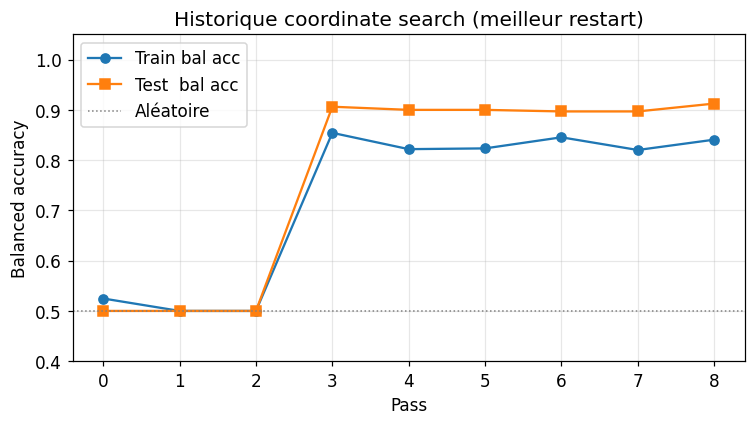

In [10]:
m_train = evaluate_network(V_train, y_train, signs, widths)
m_test  = evaluate_network(V_test,  y_test,  signs, widths)
print_results('TRAIN (déterministe)', m_train)
print_results('TEST  (déterministe)', m_test)

m_train_rob = evaluate_network(V_train, y_train, signs, widths,
                                noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
m_test_rob  = evaluate_network(V_test,  y_test,  signs, widths,
                                noise_std=NOISE_STD_HZ, n_mc=N_MC_EVAL)
print_results('TRAIN (robuste MC)', m_train_rob)
print_results('TEST  (robuste MC)', m_test_rob)

if history:
    passes = [h['pass'] for h in history]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(passes, [h['tr_bal_acc'] for h in history], 'o-', label='Train bal acc')
    ax.plot(passes, [h['va_bal_acc'] for h in history], 's-', label='Test  bal acc')
    ax.axhline(0.5, color='gray', ls=':', lw=1, label='Aléatoire')
    ax.set_xlabel('Pass')
    ax.set_ylabel('Balanced accuracy')
    ax.set_title('Historique coordinate search (meilleur restart)')
    ax.set_ylim(0.4, 1.05)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 10. Carte de décision

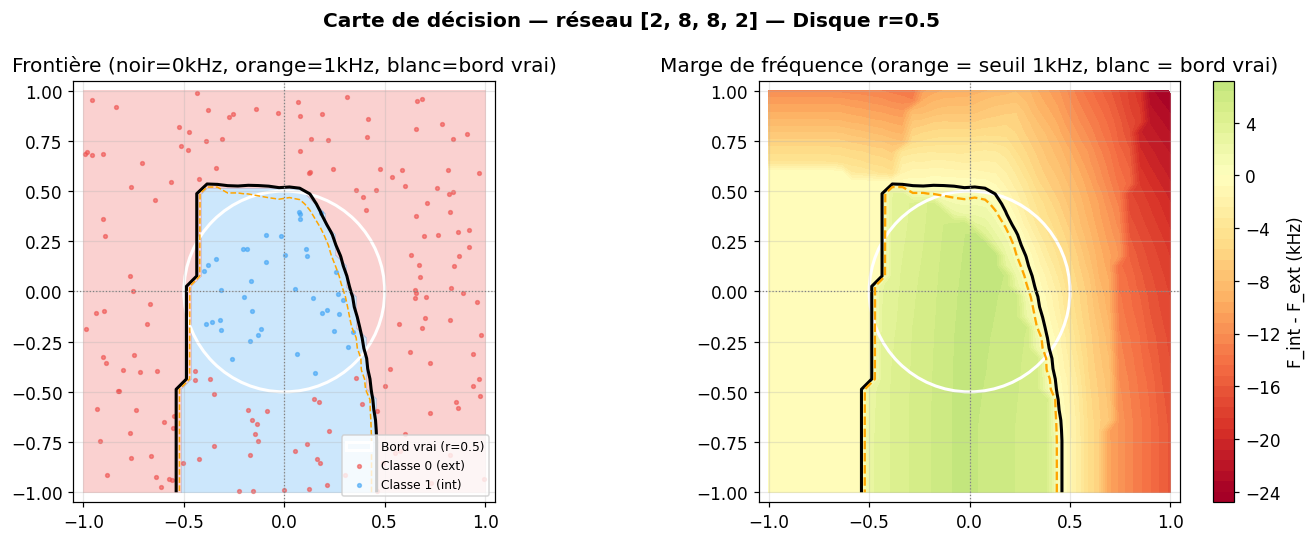

In [11]:
resolution = 40
xs = np.linspace(-1, 1, resolution)
ys = np.linspace(-1, 1, resolution)
XX, YY = np.meshgrid(xs, ys)
grid_V = xy_to_voltage(np.column_stack([XX.ravel(), YY.ravel()]))

Fout_grid   = network_forward_dataset(grid_V, signs, widths)
pred_grid   = np.argmax(Fout_grid, axis=1).reshape(XX.shape)
margin_grid = (Fout_grid[:, 1] - Fout_grid[:, 0]).reshape(XX.shape) * 1e-3

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f'Carte de décision — réseau {LAYER_SIZES} — Disque r={DISK_RADIUS}',
             fontweight='bold')

ax = axes[0]
ax.contourf(XX, YY, pred_grid, levels=[-0.5, 0.5, 1.5],
            colors=['#EF535044', '#42A5F544'])
ax.contour(XX, YY, margin_grid, levels=[0], colors='k', linewidths=2)
ax.contour(XX, YY, margin_grid, levels=[1.0], colors='orange',
           linewidths=1, linestyles='--')
# Cercle de référence (bord vrai du disque)
circle_ref = plt.Circle((0, 0), DISK_RADIUS, color='white', fill=False,
                          lw=2, ls='-', label=f'Bord vrai (r={DISK_RADIUS})')
ax.add_patch(circle_ref)
ax.scatter(X_test[y_test==0, 0], X_test[y_test==0, 1],
           s=6, c='#EF5350', alpha=0.6, label='Classe 0 (ext)')
ax.scatter(X_test[y_test==1, 0], X_test[y_test==1, 1],
           s=6, c='#42A5F5', alpha=0.6, label='Classe 1 (int)')
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title('Frontière (noir=0kHz, orange=1kHz, blanc=bord vrai)')
ax.set_aspect('equal')
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1]
vmax = max(abs(float(margin_grid.min())), abs(float(margin_grid.max())), 1.0)
cf = ax.contourf(XX, YY, margin_grid, levels=50, cmap='RdYlGn', vmin=-vmax, vmax=vmax)
plt.colorbar(cf, ax=ax, label='F_int - F_ext (kHz)')
ax.contour(XX, YY, margin_grid, levels=[0], colors='k', linewidths=2)
ax.contour(XX, YY, margin_grid, levels=[1.0], colors='orange',
           linewidths=1.5, linestyles='--')
circle_ref2 = plt.Circle((0, 0), DISK_RADIUS, color='white', fill=False,
                           lw=2, ls='-')
ax.add_patch(circle_ref2)
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.axvline(0, color='gray', lw=0.8, ls=':')
ax.set_title('Marge de fréquence (orange = seuil 1kHz, blanc = bord vrai)')
ax.set_aspect('equal')
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-1.05, 1.05)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Diagnostic Cadence — plages de courant

**FIX v4.1** : Les courants négatifs signalent des neurones silencieux (comportement valide).

In [12]:
print('=' * 65)
print('  DIAGNOSTIC — Itot par couche vs plage neurone')
print('  Plage neurone : ['
      + str(round(NEURON_I_AXIS[0]*1e12, 1)) + ' pA, '
      + str(round(NEURON_I_AXIS[-1]*1e12, 1)) + ' pA]')
print('  Neurones silencieux si Itot < rheobase = '
      + str(round(NEURON_I_RHEOBASE*1e12, 2)) + ' pA → Fout = 0 Hz')
print('=' * 65)

all_itot = [[] for _ in range(len(LAYER_SIZES) - 1)]
for Vin in V_train:
    F = np.array([input_f_of_v(v) for v in Vin])
    for li, (sm, wm) in enumerate(zip(signs, widths)):
        F, _, Itot = layer_forward(F, sm, wm)
        all_itot[li].extend(Itot.tolist())

n_lo = NEURON_I_AXIS[0]
n_hi = NEURON_I_AXIS[-1]
for li, itots in enumerate(all_itot):
    itots  = np.array(itots)
    lo, hi = itots.min(), itots.max()
    pct_in_range = 100 * np.mean((itots >= n_lo) & (itots <= n_hi))
    pct_silent   = 100 * np.mean(itots < n_lo)
    pct_sat      = 100 * np.mean(itots > n_hi)

    if pct_silent > 0 and pct_sat == 0:
        status = f'OK ({pct_silent:.1f}% silencieux → 0Hz, comportement normal)'
    elif pct_sat > 0:
        status = f'ATTENTION {pct_sat:.1f}% saturés (au-dessus plage Cadence)'
    else:
        status = 'OK — tous dans la plage'

    print(f'  Couche {li}: Itot in [{lo*1e12:.1f}, {hi*1e12:.1f}] pA')
    print(f'          -> {status}')

print('=' * 65)
print('Courants > plage haute = saturation sur Cadence (problème).')
print('Courants < rheobase   = neurone silencieux (Fout=0, comportement attendu).')

  DIAGNOSTIC — Itot par couche vs plage neurone
  Plage neurone : [3.0 pA, 1000.0 pA]
  Neurones silencieux si Itot < rheobase = 3.0 pA → Fout = 0 Hz
  Couche 0: Itot in [-40.6, 448.7] pA
          -> OK (25.0% silencieux → 0Hz, comportement normal)
  Couche 1: Itot in [354.6, 2408.3] pA
          -> ATTENTION 45.4% saturés (au-dessus plage Cadence)
  Couche 2: Itot in [-8.5, 24.1] pA
          -> OK (47.5% silencieux → 0Hz, comportement normal)
Courants > plage haute = saturation sur Cadence (problème).
Courants < rheobase   = neurone silencieux (Fout=0, comportement attendu).


## 12. Export des poids pour Cadence

In [13]:
layer_names = (['In->H1']
               + ['H' + str(k) + '->H' + str(k+1) for k in range(1, len(signs) - 1)]
               + ['H' + str(len(signs) - 1) + '->Out'])

print('\n=== POIDS FINAUX réseau ' + str(LAYER_SIZES) + ' — Disque r=' + str(DISK_RADIUS) + ' ===')
for k, (s, w, ln) in enumerate(zip(signs, widths, layer_names)):
    print(f'\n  Couche {k+1} [{ln}]  {s.shape[0]}->{s.shape[1]}')
    print('    Signes :\n' + str(s))
    print('    Largeurs (um) :\n' + str(w))
    print('    EXC=' + str(int((s == +1).sum()))
          + '  INH=' + str(int((s == -1).sum())))

rows = []
for li, (s, w) in enumerate(zip(signs, widths)):
    n_in, n_out = s.shape
    for i in range(n_in):
        for j in range(n_out):
            rows.append({
                'layer':    li + 1,
                'pre':      i,
                'post':     j,
                'sign':     int(s[i, j]),
                'width_um': float(w[i, j]),
                'type':     'EXC' if s[i, j] == 1 else 'INH'
            })

df_weights = pd.DataFrame(rows)
df_weights.to_csv('weights_cadence_disk.csv', index=False)
print('\nweights_cadence_disk.csv généré :')
print(df_weights.to_string(index=False))


=== POIDS FINAUX réseau [2, 8, 8, 2] — Disque r=0.5 ===

  Couche 1 [In->H1]  2->8
    Signes :
[[-1 -1  1  1 -1  1  1  1]
 [-1  1 -1 -1 -1  1 -1 -1]]
    Largeurs (um) :
[[0.1805 0.7724 2.397  0.2858 0.2716 0.135  0.2858 1.794 ]
 [0.8179 0.7382 0.135  0.5447 0.2716 0.2858 0.1805 0.2261]]
    EXC=7  INH=9

  Couche 2 [H1->H2]  8->8
    Signes :
[[ 1 -1  1  1  1 -1  1 -1]
 [-1  1  1 -1 -1 -1 -1 -1]
 [-1  1  1  1  1  1  1 -1]
 [-1  1 -1 -1 -1  1 -1  1]
 [ 1  1  1 -1  1 -1  1  1]
 [-1  1  1 -1  1  1 -1 -1]
 [ 1  1  1  1  1 -1 -1  1]
 [ 1 -1 -1  1  1 -1  1 -1]]
    Largeurs (um) :
[[2.849  0.3171 1.492  1.191  2.698  0.135  2.548  0.8634]
 [0.6813 1.944  0.2858 0.8634 0.7724 0.5903 0.6813 0.4082]
 [0.2716 2.397  1.191  1.341  2.849  0.2858 3.     1.    ]
 [0.1805 0.2858 0.8179 0.4082 0.1805 0.4366 0.5447 2.397 ]
 [2.548  1.191  1.492  0.4992 2.095  0.2261 1.944  0.2858]
 [0.5447 2.548  0.2858 0.7268 0.2858 1.04   0.9545 0.5903]
 [2.246  1.944  1.794  0.5874 0.4366 0.6358 0.1805 1.04  ]
 [